# 04 · Chunking dos precedentes

Este notebook divide os registros do JSONL único (notebook 03) em **trechos**, que são as unidades da busca. A EDA (notebook 02) mostrou que os precedentes são curtos, com mediana de cerca de 100 tokens por enunciado. Por isso a divisão é simples e segue a estrutura do próprio texto.

| Decisão | Regra | Por quê |
|---|---|---|
| O que entra | Só os registros **buscáveis** (vigentes, com tese fixada ou afetados sem tese) | Cancelados, suspensos, superados e em quarentena não podem ser entregues como regra. Eles ficam registrados no JSONL e na tabela de registros (notebook 05), fora do índice |
| Unidade | Um trecho por enunciado. Súmula ou OJ com itens: **um trecho por item**. Tema: questão jurídica e tese juntas | A pergunta costuma tocar um item específico, como a Súmula 338, I ou III. Separar os itens evita que um item irrelevante dilua o vetor |
| Caput antes dos itens | É repetido no início de cada item | Sem ele, o item perde o sentido. Exemplo: OJ 225 da SBDI-1, "Celebrado contrato de concessão...: I - ..." |
| Cabeçalho | Todo trecho começa com "[Súmula 338 do TST — TÍTULO — item I]" | O trecho se explica sozinho na busca, no reranker e no prompt, e o nome de citação fica junto do texto |
| Tamanho | Até **220 tokens** (tokenizador do BGE-M3), com o cabeçalho incluído. Acima disso, o texto é dividido por frases, com o cabeçalho repetido e "parte k de n" | O reranker lê 256 tokens por par pergunta–trecho. Descontada a pergunta, um trecho de até 220 tokens é lido inteiro |
| Entrega | A busca encontra o trecho, mas o modelo recebe o **registro inteiro**, com todos os itens e o nome de citação | É o mesmo padrão da legislação, que busca no parágrafo e entrega o artigo. O item encontrado indica onde está a regra, mas o enunciado completo evita perder condições de outros itens |

### Dados desta etapa

| | Caminho no repositório | Formato | Quantidade | Versionado? |
|---|---|---|---|---|
| Entrada | `data/processed/precedentes/precedentes_tst.jsonl` | JSONL (um registro JSON por linha) | 1.493 registros (1.022 buscáveis) | fora do Git |
| Saída | `data/processed/precedentes/chunks_precedentes.jsonl` | JSONL (um registro JSON por linha) | **1.268 trechos** (442 de súmulas, 425 de OJs, 401 de temas) | fora do Git |
| Relatórios | `reports/precedentes/chunking/` | CSV, JSON e PNG | contagens.csv (3 linhas: uma por tipo), manifesto_chunking.json, tokens_trechos.png | sim |

**Formato:** a base estruturada é gravada em **JSONL** (texto, um registro JSON por linha), e não em CSV, porque cada registro tem campos com listas (itens da súmula, páginas, assuntos, histórico). Os arquivos **CSV** do projeto são os relatórios em `reports/precedentes/`. Os arquivos de dados ficam em `data/`, dentro da pasta do repositório, mas **fora do Git** (`.gitignore`): contêm texto integral e são recriados pelos notebooks.

In [1]:
from pathlib import Path
import json, os, sys, hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/precedentes').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault('HF_HUB_OFFLINE', '1')
pd.set_option('display.max_colwidth', 120); pd.set_option('display.width', 250); pd.set_option('display.max_columns', None)
PROC = ROOT / 'data/processed/precedentes'
REGISTROS = PROC / 'precedentes_tst.jsonl'
TRECHOS = PROC / 'chunks_precedentes.jsonl'
REL = ROOT / 'reports/precedentes'

from transformers import AutoTokenizer
from src.integracao.recuperacao import MODELO, REVISAO
from src.precedentes import chunking as ch, estruturacao as est
registros = [json.loads(l) for l in REGISTROS.read_text(encoding='utf-8').splitlines() if l.strip()]
man_est = json.loads((REL / 'estruturacao/manifesto_estruturacao.json').read_text(encoding='utf-8'))
sha_reg = hashlib.sha256(REGISTROS.read_bytes()).hexdigest()
assert sha_reg == man_est['sha256'], 'o JSONL não é o registrado no manifesto da estruturação (rode o notebook 03)'
tok = AutoTokenizer.from_pretrained(MODELO, revision=REVISAO, local_files_only=True)
contar = lambda t: len(tok(t, add_special_tokens=False)['input_ids'])
(REL / 'chunking').mkdir(parents=True, exist_ok=True)
print(f'{len(registros)} registros ({sum(r["buscavel"] for r in registros)} buscáveis) · JSONL conferido com o manifesto do 03 · limite {ch.LIMITE_TOKENS} tokens')

1493 registros (1022 buscáveis) · JSONL conferido com o manifesto do 03 · limite 220 tokens


## 1. Geração e validação dos trechos

In [2]:
trechos = ch.gerar_trechos(registros, contar, est.sem_origem)
problemas, avisos = ch.validar(registros, trechos)
print(f'{len(trechos)} trechos de {len({t["registro_id"] for t in trechos})} registros')
print('Problemas (impedem gravar):', problemas or 'nenhum')
print(f'Trechos acima de {ch.LIMITE_TOKENS} tokens (uma única frase longa, que não se divide sem quebrar o sentido): {len(avisos)}')
for a in avisos:
    print('  ', a)

1268 trechos de 1022 registros
Problemas (impedem gravar): nenhum
Trechos acima de 220 tokens (uma única frase longa, que não se divide sem quebrar o sentido): 12
   TST-OJ-SDI1-421 parte 1: 242 tokens (frase única acima do limite)
   TST-OJ-SDI1T-69 parte 1: 223 tokens (frase única acima do limite)
   TST-IRR-1 parte 2: 337 tokens (frase única acima do limite)
   TST-IRR-3 parte 2: 248 tokens (frase única acima do limite)
   TST-IRR-3 parte 4: 252 tokens (frase única acima do limite)
   TST-IRR-6 parte 2: 330 tokens (frase única acima do limite)
   TST-IRR-18 parte 3: 384 tokens (frase única acima do limite)
   TST-IRR-31 parte 1: 429 tokens (frase única acima do limite)
   TST-IRR-42 parte 2: 299 tokens (frase única acima do limite)
   TST-IRR-213 parte 2: 281 tokens (frase única acima do limite)
   TST-IRR-214 parte 2: 221 tokens (frase única acima do limite)
   TST-IRR-299 parte 2: 288 tokens (frase única acima do limite)


A validação confere:
- todo registro buscável tem pelo menos um trecho, e nenhum registro fora da busca tem trecho;
- não há identificador repetido;
- **nenhum texto se perde na divisão:**
  - nos registros sem itens, os trechos juntos reproduzem o texto de busca;
  - nos registros por item, o caput e cada item aparecem nos trechos.

Os trechos acima do limite são frases únicas, sobretudo teses longas de temas. Elas ficam inteiras, porque cortá-las no meio quebraria a regra. Na busca semântica, o BGE-M3 lê o trecho todo. Só o reranker lê parte dele.

## 2. Distribuição

,registros,trechos,trechos_por_item,registros_divididos_em_partes,tokens_medios,tokens_max
tipo,,,,,,
OJs,396,425,46,3,110.0,242
Súmulas,307,442,193,3,88.0,212
Temas,319,401,0,37,140.0,429


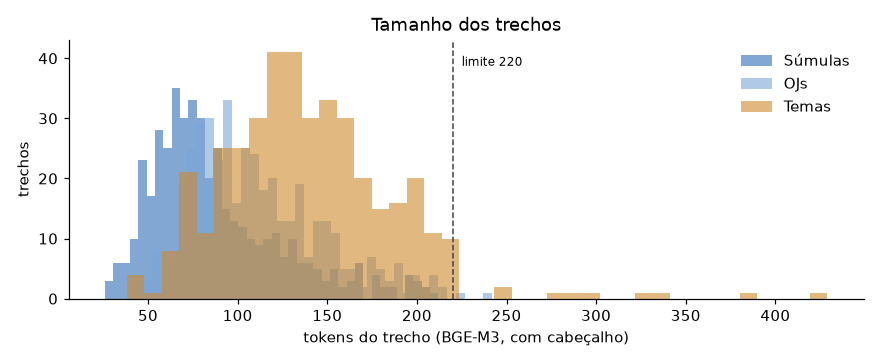

In [3]:
df = pd.DataFrame(trechos)
nomes = {'sumula': 'Súmulas', 'orientacao_jurisprudencial': 'OJs', 'tema_repetitivo': 'Temas'}
resumo = df.groupby('tipo').agg(registros=('registro_id', 'nunique'), trechos=('chunk_id', 'size'),
                                trechos_por_item=('item', lambda s: int(s.notna().sum())),
                                registros_divididos_em_partes=('partes', lambda s: int(df.loc[s.index][s > 1].registro_id.nunique())),
                                tokens_medios=('tokens', 'mean'), tokens_max=('tokens', 'max')).round(0).rename(index=nomes)
display(resumo)
resumo.to_csv(REL / 'chunking/contagens.csv', encoding='utf-8')

fig, ax = plt.subplots(figsize=(8, 3.3))
for tipo, cor in [('sumula', '#2f6db5'), ('orientacao_jurisprudencial', '#7aa6d8'), ('tema_repetitivo', '#d08a2e')]:
    ax.hist(df[df.tipo == tipo].tokens, bins=40, alpha=.6, color=cor, label=nomes[tipo])
ax.axvline(ch.LIMITE_TOKENS, color='#444', lw=1, ls='--')
ax.text(ch.LIMITE_TOKENS + 5, ax.get_ylim()[1] * .9, f'limite {ch.LIMITE_TOKENS}', fontsize=8)
ax.set_xlabel('tokens do trecho (BGE-M3, com cabeçalho)'); ax.set_ylabel('trechos')
ax.set_title('Tamanho dos trechos'); ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(REL / 'chunking/tokens_trechos.png', dpi=110)
display(fig); plt.close(fig)

## 3. Exemplos

In [4]:
def mostrar(rid, max_partes=3):
    for t in [t for t in trechos if t['registro_id'] == rid][:max_partes]:
        print(f"({t['tokens']} tokens) {t['texto'][:420]}\n")
print('— Súmula 338 (um trecho por item):\n'); mostrar('TST-SUM-338')
print('— OJ 225 da SBDI-1 (caput repetido em cada item):\n'); mostrar('TST-OJ-SDI1-225', 1)
print('— Tema 58 de IRR (questão + tese num trecho):\n'); mostrar('TST-IRR-58')
maior = df[df.partes > 1].sort_values('partes', ascending=False).iloc[0]
print(f"— {maior.nome_citacao} (tese longa dividida em {maior.partes} partes; mostrando 2):\n"); mostrar(maior.registro_id, 2)

— Súmula 338 (um trecho por item):

(107 tokens) [Súmula 338 do TST — JORNADA DE TRABALHO. REGISTRO. ÔNUS DA PROVA — item I]
É ônus do empregador que conta com mais de 10 (dez) empregados o registro da jornada de trabalho na forma do art. 74, § 2º, da CLT. A não-apresentação injustificada dos controles de frequência gera presunção relativa de veracidade da jornada de trabalho, a qual pode ser elidida por prova em contrário.

(59 tokens) [Súmula 338 do TST — JORNADA DE TRABALHO. REGISTRO. ÔNUS DA PROVA — item II]
A presunção de veracidade da jornada de trabalho, ainda que prevista em instrumento normativo, pode ser elidida por prova em contrário.

(97 tokens) [Súmula 338 do TST — JORNADA DE TRABALHO. REGISTRO. ÔNUS DA PROVA — item III]
Os cartões de ponto que demonstram horários de entrada e saída uniformes são inválidos como meio de prova, invertendo-se o ônus da prova, relativo às horas extras, que passa a ser do empregador, prevalecendo a jornada da inicial se dele não se desincumbir

## 4. Gravação e manifesto

Os trechos vão para `data/processed/precedentes/chunks_precedentes.jsonl`, fora do Git. O manifesto, que é versionado, registra:
- o hash do JSONL de trechos;
- o hash do JSONL de registros de origem;
- os parâmetros;
- as contagens.

O notebook 05 confere esse hash antes de gerar os vetores.

> **Grava:** `data/processed/precedentes/chunks_precedentes.jsonl` (JSONL, 1.268 linhas, fora do Git) e `reports/precedentes/chunking/manifesto_chunking.json`

In [5]:
if problemas:
    raise ValueError(f'{len(problemas)} problemas; nada foi gravado')
sha_tr = ch.gravar_jsonl(trechos, TRECHOS)
manifesto = dict(arquivo=str(TRECHOS.relative_to(ROOT)).replace('\\', '/'), sha256=sha_tr, trechos=len(trechos),
                 registros=int(df.registro_id.nunique()), registros_jsonl_sha256=sha_reg, limite_tokens=ch.LIMITE_TOKENS,
                 tokenizador=f'{MODELO}@{REVISAO}', acima_do_limite=len(avisos),
                 regras=['um trecho por enunciado; por item em súmulas e OJs com itens; caput repetido em cada item',
                         'cabeçalho com nome de citação, título e item', 'divisão por frases acima do limite',
                         'só registros buscáveis'])
(REL / 'chunking/manifesto_chunking.json').write_text(json.dumps(manifesto, indent=2, ensure_ascii=False), encoding='utf-8')
print(json.dumps(manifesto, indent=2, ensure_ascii=False))

{
  "arquivo": "data/processed/precedentes/chunks_precedentes.jsonl",
  "sha256": "c6a0c5d2d9da0782cedbf658291aeff6de8f1509d089024a904fde2d3101e06a",
  "trechos": 1268,
  "registros": 1022,
  "registros_jsonl_sha256": "2884779dbbd4cf4b657e6f4a8405872c45cceef21e38429d215c2776f109591b",
  "limite_tokens": 220,
  "tokenizador": "BAAI/bge-m3@5617a9f61b028005a4858fdac845db406aefb181",
  "acima_do_limite": 12,
  "regras": [
    "um trecho por enunciado; por item em súmulas e OJs com itens; caput repetido em cada item",
    "cabeçalho com nome de citação, título e item",
    "divisão por frases acima do limite",
    "só registros buscáveis"
  ]
}


## Conclusões

- **Cerca de 1,3 mil trechos**, a partir dos 1.022 registros buscáveis:
  - as súmulas e OJs com itens viram um trecho por item;
  - as teses longas de temas são divididas por frases;
  - o restante fica em um trecho por enunciado.
- **Cada trecho é legível sozinho.** O cabeçalho traz o nome de citação e o título, e o caput se repete nos itens. Isso ajuda o reranker e o prompt, que vai citar "Súmula 338, I, do TST".
- **Nada se perdeu na divisão.** A validação confere o texto de cada registro.

Próximo: `05_embeddings_indexacao_precedentes.ipynb`.